# Trend Analysis and Forecasting for Technology Intelligence

**Colab-ready notebook generated for your dataset (`Series2.xlsx`).**

This notebook implements the measurements covered in the slide deck, step by step:

1. Data loading and preprocessing  
2. Exploratory trend analysis  
3. Growth, CAGR, acceleration, and log transformation  
4. Mann-Kendall, Sen's slope, Spearman trend test  
5. Linear OLS model and diagnostics  
6. Nonlinear models: polynomial, exponential, power law, logarithmic, logistic, Gompertz  
7. Structural breaks: Chow test and multiple break detection  
8. Model evaluation: R², RMSE, MAE, MAPE, SSE, AIC, BIC  
9. Out-of-sample validation and expanding-window validation  
10. ARIMA forecasting  
11. Final model comparison and decision support

**Expected input columns:** `Year` and `Count`.  
If your file uses different names, change `YEAR_COL` and `VALUE_COL` in Section 1.


In [ ]:
# ============================================================
# 0. COLAB SETUP
# ============================================================
# Run this cell first in Google Colab.

!pip -q install openpyxl scipy statsmodels scikit-learn ruptures matplotlib pandas numpy

# Optional: Prophet can be slow to install. Uncomment if needed.
# !pip -q install prophet


In [1]:
# ============================================================
# 1. IMPORTS AND GLOBAL SETTINGS
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from scipy.optimize import curve_fit

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit

import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox, linear_reset
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA

try:
    import ruptures as rpt
    HAS_RUPTURES = True
except Exception:
    HAS_RUPTURES = False

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


## 1. Load the dataset

Upload `Series2.xlsx` to Colab, or place it in the same directory as the notebook.

The code expects two columns:

- `Year`
- `Count`

You can change these names below if needed.


In [5]:
# ============================================================
# 1. LOAD DATA
# ============================================================

# OPTION A: If running in Colab and the file is not uploaded yet, uncomment:
# from google.colab import files
# uploaded = files.upload()

FILE_PATH = "/content/Series2.xlsx"
YEAR_COL = "Year"
VALUE_COL = "Count"

df_raw = pd.read_excel(FILE_PATH)

print("Raw shape:", df_raw.shape)
print("Columns:", list(df_raw.columns))
display(df_raw.head())

# Basic validation
assert YEAR_COL in df_raw.columns, f"Missing year column: {YEAR_COL}"
assert VALUE_COL in df_raw.columns, f"Missing value column: {VALUE_COL}"

Raw shape: (41, 2)
Columns: ['Year', 'Count']


,Year,Count
0,1985,1
1,1987,4
2,1988,2
3,1989,18
4,1990,36


In [6]:
# ============================================================
# 2. BASIC PREPROCESSING
# ============================================================

df = df_raw[[YEAR_COL, VALUE_COL]].copy()
df.columns = ["year", "count"]

df["year"] = pd.to_numeric(df["year"], errors="coerce").astype("Int64")
df["count"] = pd.to_numeric(df["count"], errors="coerce")

df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)
df = df.groupby("year", as_index=False)["count"].sum()
df = df.sort_values("year").reset_index(drop=True)

# Fill missing years with zero or interpolation depending on your theoretical choice.
# For patent/publication annual counts, missing intermediate years usually mean zero observed records.
full_years = pd.DataFrame({"year": np.arange(df["year"].min(), df["year"].max() + 1)})
df = full_years.merge(df, on="year", how="left")
df["count"] = df["count"].fillna(0)

# Add time index starting at 0. This avoids numerical instability in nonlinear models.
df["t"] = np.arange(len(df))
df["count_log"] = np.log1p(df["count"])  # log(1 + count), safe when count=0

print("Processed shape:", df.shape)
display(df.head())
display(df.tail())


Processed shape: (42, 4)


,year,count,t,count_log
0,1985,1.0,0,0.693147
1,1986,0.0,1,0.000000
2,1987,4.0,2,1.609438
3,1988,2.0,3,1.098612
4,1989,18.0,4,2.944439


,year,count,t,count_log
37,2022,1999.0,37,7.600902
38,2023,2279.0,38,7.731931
39,2024,2376.0,39,7.773594
40,2025,2294.0,40,7.738488
41,2026,144.0,41,4.976734


## 2. Exploratory trend analysis

This section corresponds to the early sessions in the slide deck:

- raw line plot  
- log-scale plot  
- first differences  
- growth rates  
- acceleration  
- CAGR


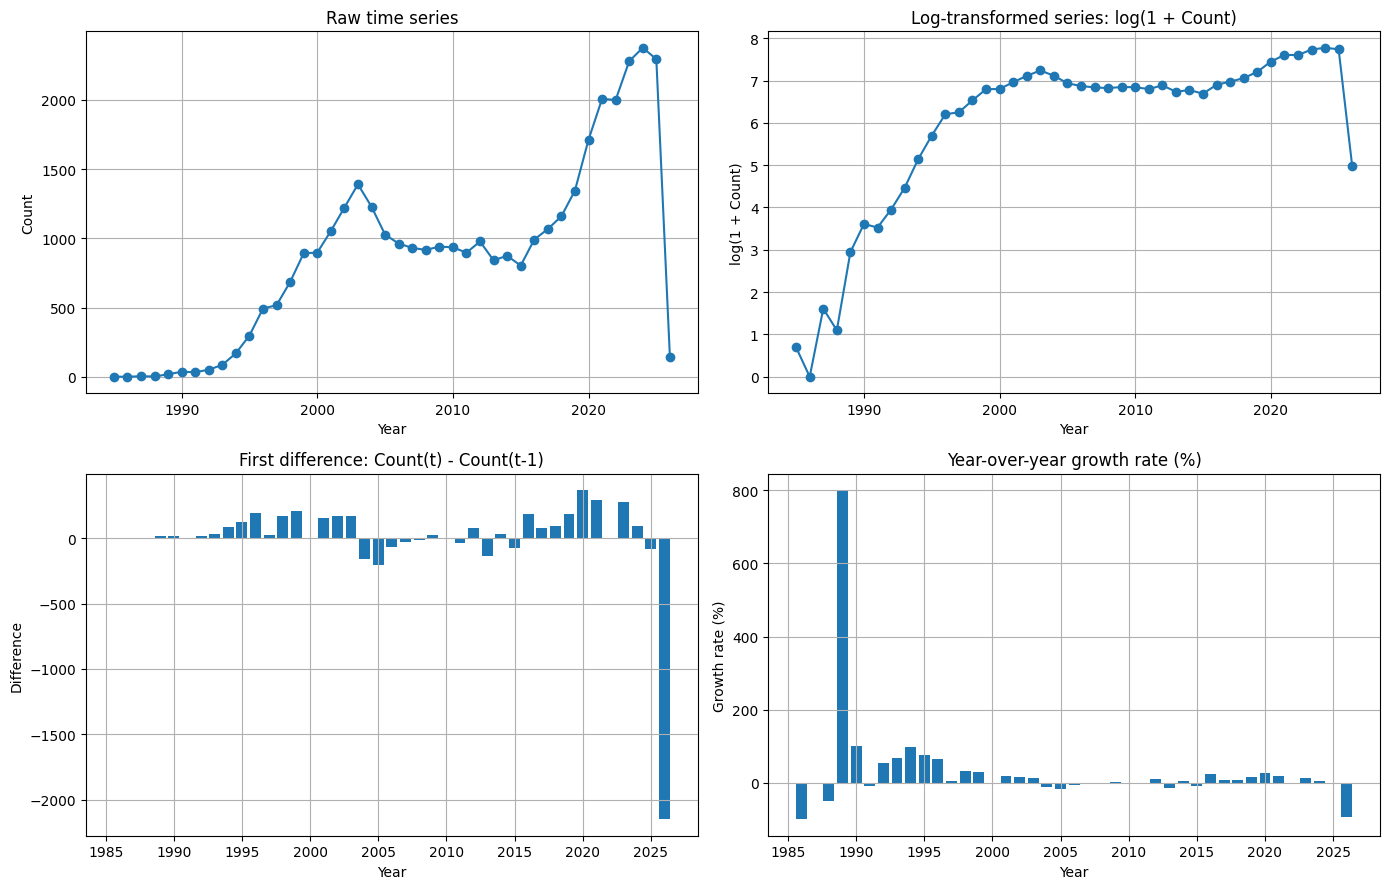

In [7]:
# ============================================================
# 3. EXPLORATORY PLOTS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(df["year"], df["count"], marker="o")
axes[0, 0].set_title("Raw time series")
axes[0, 0].set_xlabel("Year")
axes[0, 0].set_ylabel("Count")

axes[0, 1].plot(df["year"], df["count_log"], marker="o")
axes[0, 1].set_title("Log-transformed series: log(1 + Count)")
axes[0, 1].set_xlabel("Year")
axes[0, 1].set_ylabel("log(1 + Count)")

df["diff"] = df["count"].diff()
axes[1, 0].bar(df["year"], df["diff"])
axes[1, 0].set_title("First difference: Count(t) - Count(t-1)")
axes[1, 0].set_xlabel("Year")
axes[1, 0].set_ylabel("Difference")

df["growth_rate"] = df["count"].pct_change().replace([np.inf, -np.inf], np.nan)
axes[1, 1].bar(df["year"], df["growth_rate"] * 100)
axes[1, 1].set_title("Year-over-year growth rate (%)")
axes[1, 1].set_xlabel("Year")
axes[1, 1].set_ylabel("Growth rate (%)")

plt.tight_layout()
plt.show()


,metric,value
0,first_nonzero_year,1985.000000
1,first_nonzero_count,1.000000
2,last_year,2026.000000
3,last_count,144.000000
4,period_length_years,41.000000
5,CAGR,0.128868


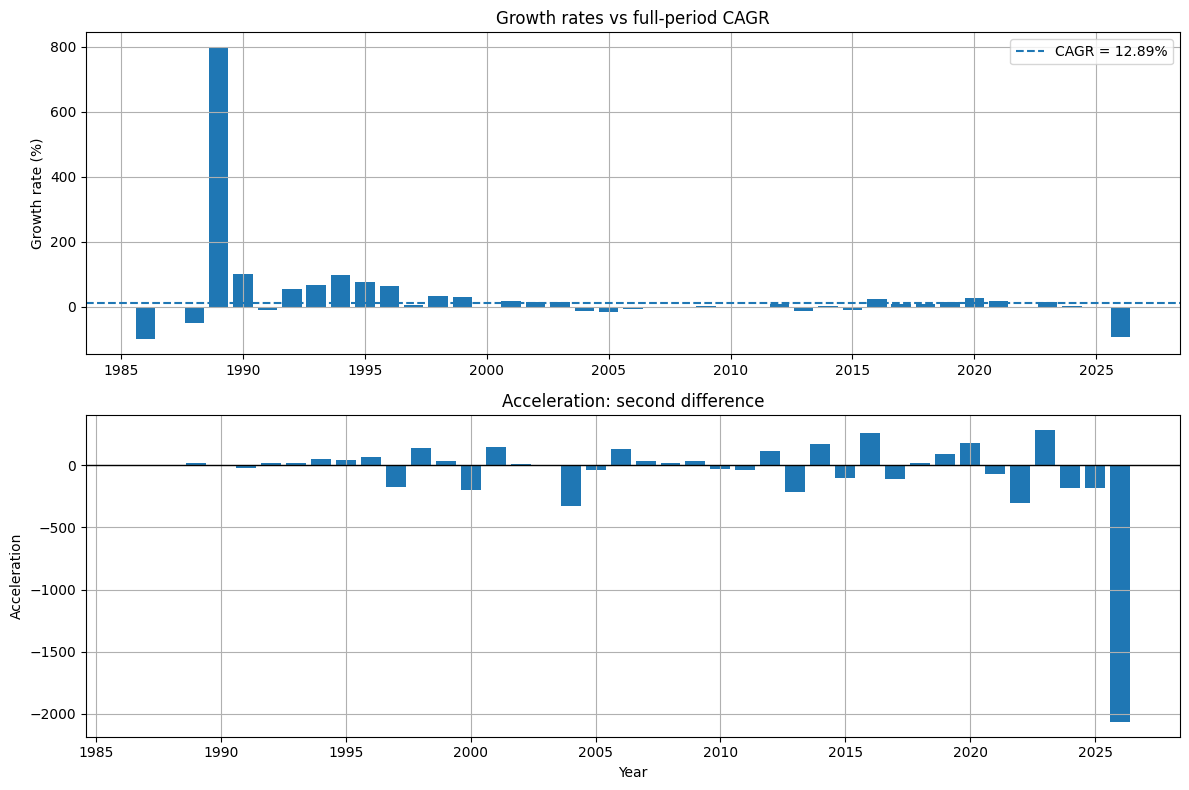

In [8]:
# ============================================================
# 4. GROWTH, CAGR, ACCELERATION
# ============================================================

df["acceleration"] = df["count"] - 2 * df["count"].shift(1) + df["count"].shift(2)

start_count = df.loc[df["count"] > 0, "count"].iloc[0]
start_year = df.loc[df["count"] > 0, "year"].iloc[0]
end_count = df["count"].iloc[-1]
end_year = df["year"].iloc[-1]
n_years = end_year - start_year

cagr = (end_count / start_count) ** (1 / n_years) - 1 if start_count > 0 and n_years > 0 else np.nan

summary_growth = pd.DataFrame({
    "metric": [
        "first_nonzero_year", "first_nonzero_count", "last_year", "last_count",
        "period_length_years", "CAGR"
    ],
    "value": [start_year, start_count, end_year, end_count, n_years, cagr]
})

display(summary_growth)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].bar(df["year"], df["growth_rate"] * 100)
axes[0].axhline(cagr * 100, linestyle="--", label=f"CAGR = {cagr*100:.2f}%")
axes[0].set_title("Growth rates vs full-period CAGR")
axes[0].set_ylabel("Growth rate (%)")
axes[0].legend()

axes[1].bar(df["year"], df["acceleration"])
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Acceleration: second difference")
axes[1].set_ylabel("Acceleration")
axes[1].set_xlabel("Year")

plt.tight_layout()
plt.show()


## 3. Smoothing and moving averages

The slides cover SMA, WMA, and EMA. These are useful for visualizing trend without fitting a full model.


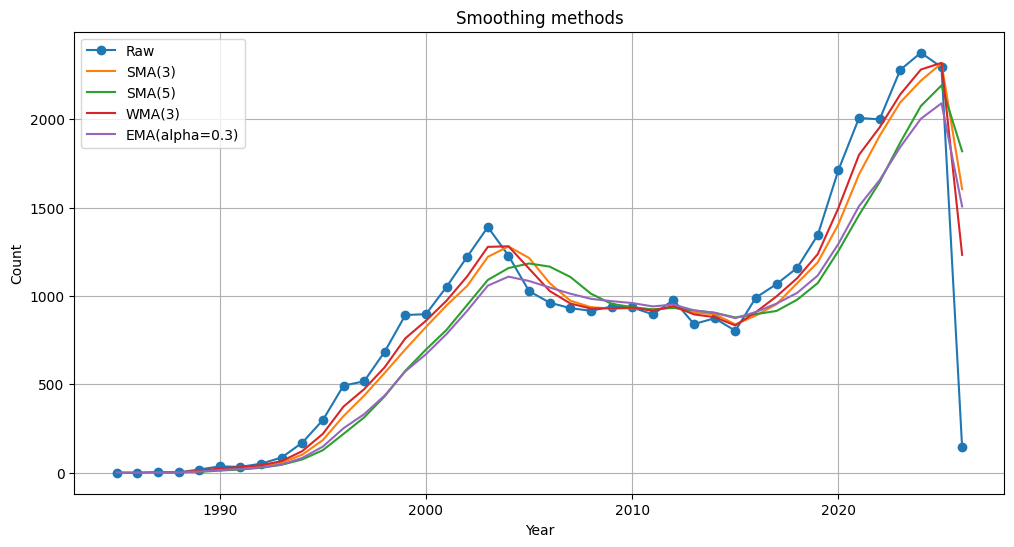

In [9]:
# ============================================================
# 5. MOVING AVERAGES AND SMOOTHING
# ============================================================

def weighted_moving_average(x, window):
    weights = np.arange(1, window + 1)
    return x.rolling(window).apply(lambda values: np.dot(values, weights) / weights.sum(), raw=True)

df["sma_3"] = df["count"].rolling(3).mean()
df["sma_5"] = df["count"].rolling(5).mean()
df["wma_3"] = weighted_moving_average(df["count"], 3)
df["ema_03"] = df["count"].ewm(alpha=0.3, adjust=False).mean()

plt.figure(figsize=(12, 6))
plt.plot(df["year"], df["count"], marker="o", label="Raw")
plt.plot(df["year"], df["sma_3"], label="SMA(3)")
plt.plot(df["year"], df["sma_5"], label="SMA(5)")
plt.plot(df["year"], df["wma_3"], label="WMA(3)")
plt.plot(df["year"], df["ema_03"], label="EMA(alpha=0.3)")
plt.title("Smoothing methods")
plt.xlabel("Year")
plt.ylabel("Count")
plt.legend()
plt.show()


## 4. Statistical trend detection

Implemented:

- Mann-Kendall test  
- Sen's slope  
- Spearman rank trend test  
- ADF and KPSS stationarity checks


In [10]:
# ============================================================
# 6. MANN-KENDALL TEST AND SEN'S SLOPE
# ============================================================

def mann_kendall_test(x):
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    n = len(x)
    s = 0
    for k in range(n - 1):
        s += np.sum(np.sign(x[k+1:] - x[k]))
    unique_x, counts = np.unique(x, return_counts=True)
    tie_sum = np.sum(counts * (counts - 1) * (2 * counts + 5))
    var_s = (n * (n - 1) * (2 * n + 5) - tie_sum) / 18
    if s > 0:
        z = (s - 1) / np.sqrt(var_s)
    elif s < 0:
        z = (s + 1) / np.sqrt(var_s)
    else:
        z = 0
    p = 2 * (1 - stats.norm.cdf(abs(z)))
    trend = "increasing" if z > 0 and p < 0.05 else "decreasing" if z < 0 and p < 0.05 else "no significant trend"
    return {"S": s, "Var(S)": var_s, "Z": z, "p_value": p, "trend": trend}

def sens_slope(y, x=None):
    y = np.asarray(y, dtype=float)
    if x is None:
        x = np.arange(len(y))
    else:
        x = np.asarray(x, dtype=float)
    slopes = []
    for i in range(len(y) - 1):
        for j in range(i + 1, len(y)):
            if x[j] != x[i]:
                slopes.append((y[j] - y[i]) / (x[j] - x[i]))
    slopes = np.asarray(slopes)
    return np.nanmedian(slopes), np.nanpercentile(slopes, [2.5, 97.5])

mk_result = mann_kendall_test(df["count"])
sen, sen_ci = sens_slope(df["count"], df["year"])

spearman_rho, spearman_p = stats.spearmanr(df["year"], df["count"])

trend_tests = pd.DataFrame([
    {"test": "Mann-Kendall", **mk_result},
    {"test": "Sen's slope", "S": np.nan, "Var(S)": np.nan, "Z": np.nan, "p_value": np.nan, "trend": f"{sen:.4f} per year; 95% empirical CI [{sen_ci[0]:.4f}, {sen_ci[1]:.4f}]"},
    {"test": "Spearman", "S": np.nan, "Var(S)": np.nan, "Z": spearman_rho, "p_value": spearman_p, "trend": "rank correlation year-count"}
])

display(trend_tests)


,test,S,Var(S),Z,p_value,trend
0,Mann-Kendall,571.0,8514.333333,6.177312,6.520218e-10,increasing
1,Sen's slope,NaN,NaN,NaN,NaN,"45.0952 per year; 95% empirical CI [-73.0000, ..."
2,Spearman,NaN,NaN,0.786079,6.912411e-10,rank correlation year-count


In [11]:
# ============================================================
# 7. STATIONARITY CHECKS: ADF AND KPSS
# ============================================================

def run_adf(series, name):
    series = pd.Series(series).dropna()
    result = adfuller(series, autolag="AIC")
    return {
        "series": name,
        "test": "ADF",
        "statistic": result[0],
        "p_value": result[1],
        "interpretation": "stationary" if result[1] < 0.05 else "non-stationary"
    }

def run_kpss(series, name):
    series = pd.Series(series).dropna()
    try:
        result = kpss(series, regression="c", nlags="auto")
        return {
            "series": name,
            "test": "KPSS",
            "statistic": result[0],
            "p_value": result[1],
            "interpretation": "non-stationary" if result[1] < 0.05 else "stationary"
        }
    except Exception as e:
        return {"series": name, "test": "KPSS", "statistic": np.nan, "p_value": np.nan, "interpretation": str(e)}

stationarity = pd.DataFrame([
    run_adf(df["count"], "count"),
    run_kpss(df["count"], "count"),
    run_adf(df["count"].diff(), "first difference"),
    run_kpss(df["count"].diff(), "first difference"),
    run_adf(df["count_log"], "log(1+count)"),
    run_kpss(df["count_log"], "log(1+count)")
])

display(stationarity)


/tmp/ipykernel_6805/3950500981.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(series, regression="c", nlags="auto")


,series,test,statistic,p_value,interpretation
0,count,ADF,-1.589707,0.488762,non-stationary
1,count,KPSS,0.711141,0.012533,non-stationary
2,first difference,ADF,-2.618941,0.089145,non-stationary
3,first difference,KPSS,0.180876,0.100000,stationary
4,log(1+count),ADF,-2.803739,0.057742,non-stationary
5,log(1+count),KPSS,0.653405,0.017781,non-stationary


## 5. Linear OLS trend model and diagnostics

This section implements the linear trend model and the diagnostic tests from the slides:

- OLS
- residual plot
- Durbin-Watson
- Breusch-Pagan
- Shapiro-Wilk
- RESET
- Cook's distance


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.644
Model:                            OLS   Adj. R-squared:                  0.635
Method:                 Least Squares   F-statistic:                     72.40
Date:                Sat, 06 Jun 2026   Prob (F-statistic):           1.64e-10
Time:                        03:19:33   Log-Likelihood:                -310.93
No. Observations:                  42   AIC:                             625.9
Df Residuals:                      40   BIC:                             629.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -33.3167    123.367     -0.270      0.7

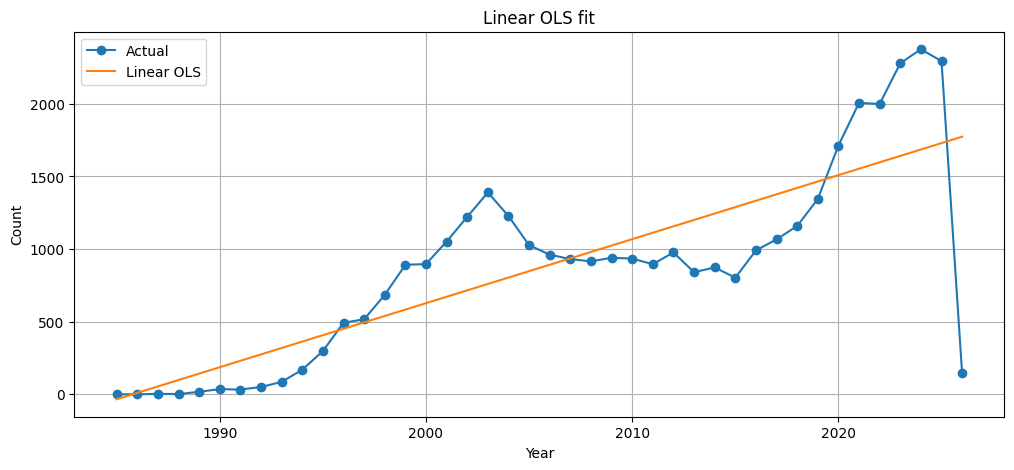

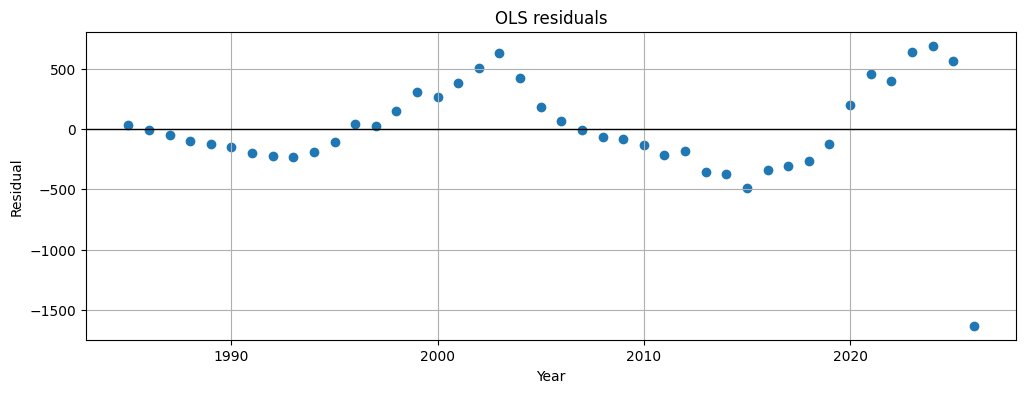

In [12]:
# ============================================================
# 8. LINEAR OLS MODEL
# ============================================================

def fit_ols(y, X, model_name="OLS"):
    X_const = sm.add_constant(X)
    model = sm.OLS(y, X_const).fit()
    yhat = model.predict(X_const)
    resid = y - yhat
    return model, yhat, resid

y = df["count"].values
X_linear = df[["t"]].values

ols_model, ols_pred, ols_resid = fit_ols(y, X_linear, "Linear OLS")
print(ols_model.summary())

plt.figure(figsize=(12, 5))
plt.plot(df["year"], y, marker="o", label="Actual")
plt.plot(df["year"], ols_pred, label="Linear OLS")
plt.title("Linear OLS fit")
plt.xlabel("Year")
plt.ylabel("Count")
plt.legend()
plt.show()

plt.figure(figsize=(12, 4))
plt.scatter(df["year"], ols_resid)
plt.axhline(0, color="black", linewidth=1)
plt.title("OLS residuals")
plt.xlabel("Year")
plt.ylabel("Residual")
plt.show()


,diagnostic,statistic,p_value,interpretation
0,Durbin-Watson,0.817103,NaN,≈2 good; <1.5 positive autocorrelation
1,Breusch-Pagan LM,6.868446,0.008773,p<0.05 heteroscedasticity
2,Shapiro-Wilk,0.878230,0.000342,p<0.05 non-normal residuals
3,RESET,0.470037,0.497026,p<0.05 functional form misspecification
4,Max Cook's distance,0.894055,NaN,most influential year = 2026


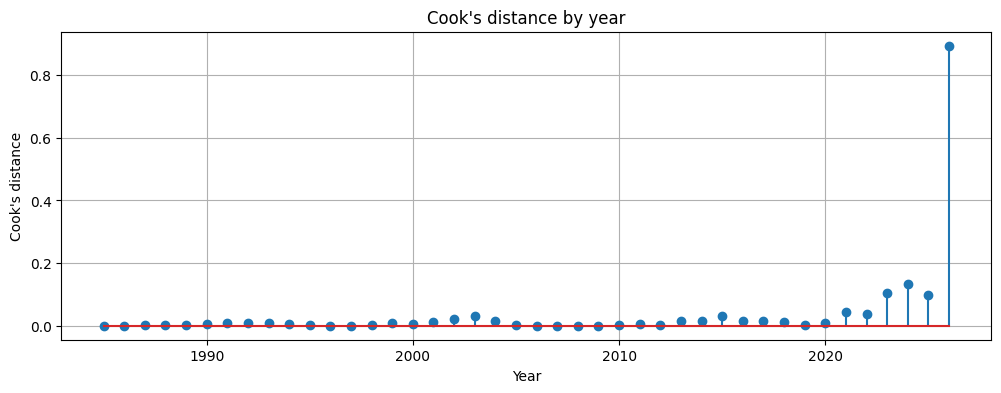

In [13]:
# ============================================================
# 9. OLS DIAGNOSTICS
# ============================================================

X_const = sm.add_constant(X_linear)

dw = durbin_watson(ols_resid)
bp_test = het_breuschpagan(ols_resid, X_const)
shapiro_stat, shapiro_p = stats.shapiro(ols_resid)

try:
    reset = linear_reset(ols_model, power=2, use_f=True)
    reset_stat, reset_p = float(reset.fvalue), float(reset.pvalue)
except Exception:
    reset_stat, reset_p = np.nan, np.nan

influence = ols_model.get_influence()
cooks_d = influence.cooks_distance[0]
max_cook_idx = int(np.argmax(cooks_d))

diagnostics = pd.DataFrame([
    {"diagnostic": "Durbin-Watson", "statistic": dw, "p_value": np.nan, "interpretation": "≈2 good; <1.5 positive autocorrelation"},
    {"diagnostic": "Breusch-Pagan LM", "statistic": bp_test[0], "p_value": bp_test[1], "interpretation": "p<0.05 heteroscedasticity"},
    {"diagnostic": "Shapiro-Wilk", "statistic": shapiro_stat, "p_value": shapiro_p, "interpretation": "p<0.05 non-normal residuals"},
    {"diagnostic": "RESET", "statistic": reset_stat, "p_value": reset_p, "interpretation": "p<0.05 functional form misspecification"},
    {"diagnostic": "Max Cook's distance", "statistic": cooks_d[max_cook_idx], "p_value": np.nan, "interpretation": f"most influential year = {df.loc[max_cook_idx, 'year']}"}
])

display(diagnostics)

plt.figure(figsize=(12, 4))
plt.stem(df["year"], cooks_d)
plt.title("Cook's distance by year")
plt.xlabel("Year")
plt.ylabel("Cook's distance")
plt.show()


## 6. Candidate trend models

Models implemented:

- Linear  
- Polynomial degree 2 and 3  
- Exponential  
- Power law  
- Logarithmic  
- Logistic S-curve  
- Gompertz S-curve  
- Piecewise linear  

All models are evaluated on the original count scale.


In [14]:
# ============================================================
# 10. MODEL HELPERS AND METRICS
# ============================================================

def safe_mape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

def smape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denom = (np.abs(y_true) + np.abs(y_pred)) / 2
    mask = denom != 0
    return np.mean(np.abs(y_true[mask] - y_pred[mask]) / denom[mask]) * 100 if mask.sum() else np.nan

def model_metrics(y_true, y_pred, k, model_name):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    resid = y_true - y_pred
    n = len(y_true)
    sse = np.sum(resid**2)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    adj_r2 = 1 - (1-r2) * (n-1) / max(n-k-1, 1)
    aic = n * np.log(max(sse/n, 1e-12)) + 2*k
    bic = n * np.log(max(sse/n, 1e-12)) + k*np.log(n)
    return {
        "model": model_name,
        "k": k,
        "R2": r2,
        "Adj_R2": adj_r2,
        "RMSE": rmse,
        "MAE": mae,
        "MAPE": safe_mape(y_true, y_pred),
        "SMAPE": smape(y_true, y_pred),
        "SSE": sse,
        "AIC": aic,
        "BIC": bic
    }

def plot_fit(model_name, y_pred):
    plt.figure(figsize=(12, 5))
    plt.plot(df["year"], df["count"], marker="o", label="Actual")
    plt.plot(df["year"], y_pred, label=model_name)
    plt.title(model_name)
    plt.xlabel("Year")
    plt.ylabel("Count")
    plt.legend()
    plt.show()


In [15]:
# ============================================================
# 11. FIT CANDIDATE MODELS
# ============================================================

t = df["t"].values.astype(float)
years = df["year"].values
y = df["count"].values.astype(float)
eps = 1e-6

predictions = {}
metrics = []

# 1. Linear
X = sm.add_constant(t)
linear_model = sm.OLS(y, X).fit()
pred_linear = linear_model.predict(X)
predictions["Linear"] = pred_linear
metrics.append(model_metrics(y, pred_linear, k=2, model_name="Linear"))

# 2. Polynomial degree 2 and 3
for degree in [2, 3]:
    X_poly = np.column_stack([t**d for d in range(1, degree+1)])
    X_poly = sm.add_constant(X_poly)
    poly_model = sm.OLS(y, X_poly).fit()
    pred = poly_model.predict(X_poly)
    predictions[f"Polynomial_{degree}"] = pred
    metrics.append(model_metrics(y, pred, k=degree+1, model_name=f"Polynomial degree {degree}"))

# 3. Exponential: log(y+1) = a + b t
logy = np.log1p(y)
exp_model = sm.OLS(logy, sm.add_constant(t)).fit()
pred_exp = np.expm1(exp_model.predict(sm.add_constant(t)))
pred_exp = np.maximum(pred_exp, 0)
predictions["Exponential"] = pred_exp
metrics.append(model_metrics(y, pred_exp, k=2, model_name="Exponential"))

# 4. Power law: log(y+1)=a + b log(t+1)
logt = np.log1p(t)
power_model = sm.OLS(logy, sm.add_constant(logt)).fit()
pred_power = np.expm1(power_model.predict(sm.add_constant(logt)))
pred_power = np.maximum(pred_power, 0)
predictions["Power_law"] = pred_power
metrics.append(model_metrics(y, pred_power, k=2, model_name="Power law"))

# 5. Logarithmic: y = a + b log(t+1)
log_model = sm.OLS(y, sm.add_constant(logt)).fit()
pred_log = log_model.predict(sm.add_constant(logt))
pred_log = np.maximum(pred_log, 0)
predictions["Logarithmic"] = pred_log
metrics.append(model_metrics(y, pred_log, k=2, model_name="Logarithmic"))

# 6. Logistic
def logistic_func(t, K, r, t0):
    return K / (1 + np.exp(-r * (t - t0)))

try:
    K0 = max(y) * 1.5 if max(y) > 0 else 1
    r0 = 0.2
    t00 = np.median(t)
    params_logistic, _ = curve_fit(
        logistic_func, t, y, p0=[K0, r0, t00],
        bounds=([max(y)*1.01, 0.0001, min(t)-20], [max(y)*100 + 1, 5, max(t)+20]),
        maxfev=20000
    )
    pred_logistic = logistic_func(t, *params_logistic)
    predictions["Logistic"] = pred_logistic
    metrics.append(model_metrics(y, pred_logistic, k=3, model_name="Logistic"))
    print("Logistic parameters K, r, t0:", params_logistic)
except Exception as e:
    print("Logistic failed:", e)

# 7. Gompertz
def gompertz_func(t, K, b, t0):
    return K * np.exp(-np.exp(-b * (t - t0)))

try:
    K0 = max(y) * 1.5 if max(y) > 0 else 1
    b0 = 0.2
    t00 = np.median(t)
    params_gompertz, _ = curve_fit(
        gompertz_func, t, y, p0=[K0, b0, t00],
        bounds=([max(y)*1.01, 0.0001, min(t)-20], [max(y)*100 + 1, 5, max(t)+20]),
        maxfev=20000
    )
    pred_gompertz = gompertz_func(t, *params_gompertz)
    predictions["Gompertz"] = pred_gompertz
    metrics.append(model_metrics(y, pred_gompertz, k=3, model_name="Gompertz"))
    print("Gompertz parameters K, b, t0:", params_gompertz)
except Exception as e:
    print("Gompertz failed:", e)

metrics_df = pd.DataFrame(metrics).sort_values("AIC")
display(metrics_df)


Logistic parameters K, r, t0: [2.39976000e+03 8.36850400e-02 2.83286596e+01]
Gompertz parameters K, b, t0: [2.39976000e+03 5.39935634e-02 2.06687050e+01]


,model,k,R2,Adj_R2,RMSE,MAE,MAPE,SMAPE,SSE,AIC,BIC
0,Linear,2,0.644115,0.625864,397.109021,283.727964,341.134839,59.329607,6.623214e+06,506.673712,510.149051
1,Polynomial degree 2,3,0.648353,0.620591,394.737414,285.486148,463.246608,58.794814,6.544340e+06,508.170545,513.383554
2,Polynomial degree 3,4,0.654045,0.616644,391.529648,277.847298,750.436279,57.666796,6.438410e+06,509.485144,516.435823
7,Gompertz,3,0.630708,0.601553,404.519552,305.158445,705.452012,61.420455,6.872715e+06,510.226806,515.439815
5,Logarithmic,2,0.605793,0.585577,417.942801,307.446343,205.946315,59.879403,7.336400e+06,510.968945,514.444284
6,Logistic,3,0.613825,0.583337,413.663055,316.273046,1098.523034,62.695401,7.186919e+06,512.104348,517.317357
4,Power law,2,0.339808,0.305952,540.866287,329.042462,99.676149,56.141927,1.228653e+07,532.626456,536.101795
3,Exponential,2,-1.159472,-1.270214,978.201734,587.073076,254.755191,80.463387,4.018890e+07,582.400137,585.875477


Cumulative Logistic parameters K, r, t0: [4.86912890e+04 1.23050908e-01 3.30172046e+01]
Cumulative Gompertz parameters K, b, t0: [8.18496167e+04 4.78278695e-02 3.71199899e+01]


,model,k,R2,Adj_R2,RMSE,MAE,MAPE,SMAPE,SSE,AIC,BIC
1,Gompertz cumulative,3,0.990153,0.989375,1132.473709,1000.620292,1735.549024,52.619331,5.386486e+07,596.701410,601.914419
0,Logistic cumulative,3,0.983737,0.982453,1455.386985,1334.691789,5366.535308,57.372892,8.896235e+07,617.774278,622.987286


Lifecycle classification based on: Gompertz cumulative
Estimated cumulative saturation level K = 81,849.62


,year,count,cumulative_count,fitted_cumulative_s_curve,saturation_share,lifecycle_stage
0,1985,1.0,1.0,223.670514,0.002733,Emergence
1,1986,0.0,1.0,294.662833,0.003600,Emergence
2,1987,4.0,5.0,383.222466,0.004682,Emergence
3,1988,2.0,7.0,492.319064,0.006015,Emergence
4,1989,18.0,25.0,625.117064,0.007637,Emergence
5,1990,36.0,61.0,784.932583,0.009590,Emergence
6,1991,33.0,94.0,975.182442,0.011914,Emergence
7,1992,51.0,145.0,1199.326829,0.014653,Emergence
8,1993,86.0,231.0,1460.807398,0.017847,Emergence
9,1994,170.0,401.0,1762.982817,0.021539,Emergence


,lifecycle_stage,start_year,end_year,n_years,min_saturation_share,max_saturation_share,observed_cum_start,observed_cum_end
0,Emergence,1985,2004,20,0.002733,0.092652,1.0,9075.0
1,Growth,2005,2026,22,0.103539,0.435775,10102.0,36550.0


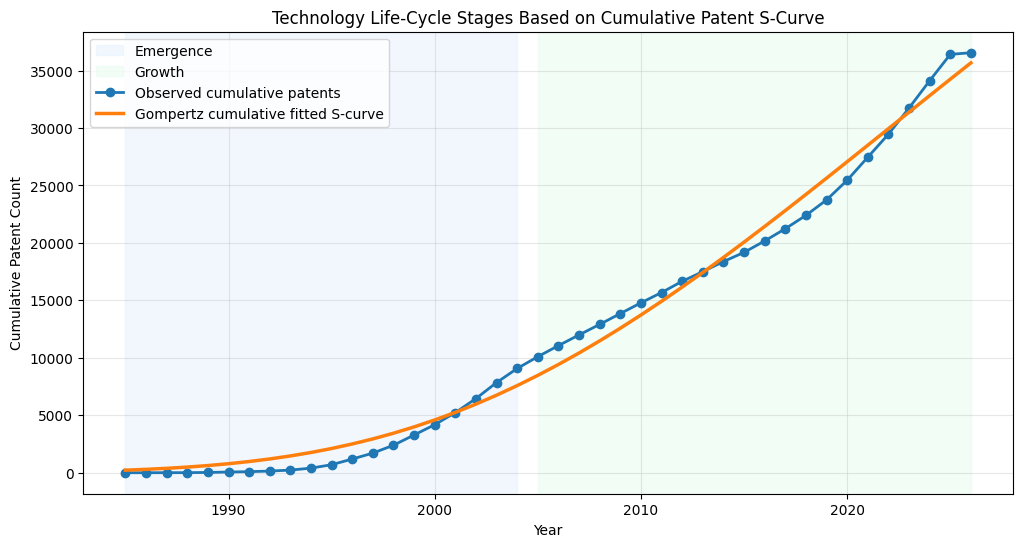

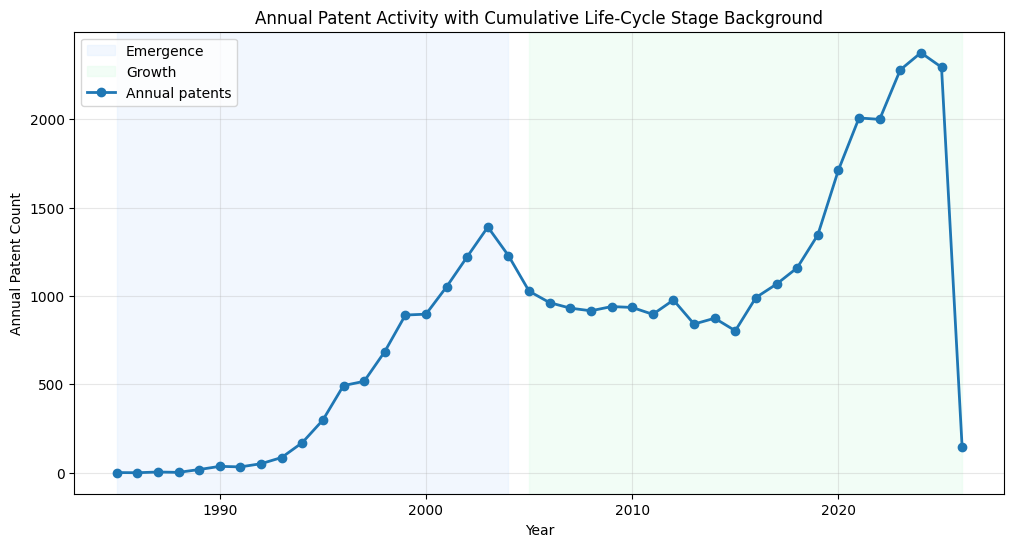

In [28]:
# ============================================================
# 11B. TECHNOLOGY LIFE-CYCLE STAGE CLASSIFICATION
# Based on CUMULATIVE patents, not annual counts
# ============================================================

# Create cumulative patent series
df["cumulative_count"] = df["count"].cumsum()

t = df["t"].values.astype(float)
cum_y = df["cumulative_count"].values.astype(float)

# ------------------------------------------------------------
# Fit Logistic / Gompertz to cumulative patents
# ------------------------------------------------------------

def logistic_func(t, K, r, t0):
    return K / (1 + np.exp(-r * (t - t0)))

def gompertz_func(t, K, b, t0):
    return K * np.exp(-np.exp(-b * (t - t0)))

cum_predictions = {}
cum_metrics = []

# Logistic on cumulative patents
try:
    K0 = max(cum_y) * 1.5
    r0 = 0.2
    t00 = np.median(t)

    params_logistic_cum, _ = curve_fit(
        logistic_func,
        t,
        cum_y,
        p0=[K0, r0, t00],
        bounds=(
            [max(cum_y) * 1.01, 0.0001, min(t) - 20],
            [max(cum_y) * 100 + 1, 5, max(t) + 20]
        ),
        maxfev=20000
    )

    pred_logistic_cum = logistic_func(t, *params_logistic_cum)
    cum_predictions["Logistic"] = pred_logistic_cum
    cum_metrics.append(
        model_metrics(cum_y, pred_logistic_cum, k=3, model_name="Logistic cumulative")
    )

    print("Cumulative Logistic parameters K, r, t0:", params_logistic_cum)

except Exception as e:
    print("Cumulative Logistic failed:", e)


# Gompertz on cumulative patents
try:
    K0 = max(cum_y) * 1.5
    b0 = 0.2
    t00 = np.median(t)

    params_gompertz_cum, _ = curve_fit(
        gompertz_func,
        t,
        cum_y,
        p0=[K0, b0, t00],
        bounds=(
            [max(cum_y) * 1.01, 0.0001, min(t) - 20],
            [max(cum_y) * 100 + 1, 5, max(t) + 20]
        ),
        maxfev=20000
    )

    pred_gompertz_cum = gompertz_func(t, *params_gompertz_cum)
    cum_predictions["Gompertz"] = pred_gompertz_cum
    cum_metrics.append(
        model_metrics(cum_y, pred_gompertz_cum, k=3, model_name="Gompertz cumulative")
    )

    print("Cumulative Gompertz parameters K, b, t0:", params_gompertz_cum)

except Exception as e:
    print("Cumulative Gompertz failed:", e)


# ------------------------------------------------------------
# Compare cumulative S-curve models
# ------------------------------------------------------------

cum_metrics_df = pd.DataFrame(cum_metrics).sort_values("AIC")
display(cum_metrics_df)

# Select best cumulative S-curve model by AIC
best_cum_model_name = cum_metrics_df.iloc[0]["model"]

if "Logistic" in best_cum_model_name:
    lifecycle_model_name = "Logistic cumulative"
    fitted_cum_curve = cum_predictions["Logistic"]
    K_est = params_logistic_cum[0]
elif "Gompertz" in best_cum_model_name:
    lifecycle_model_name = "Gompertz cumulative"
    fitted_cum_curve = cum_predictions["Gompertz"]
    K_est = params_gompertz_cum[0]
else:
    raise ValueError("No valid cumulative S-curve model selected.")


# ------------------------------------------------------------
# Lifecycle stage classification based on cumulative saturation
# ------------------------------------------------------------

df["fitted_cumulative_s_curve"] = fitted_cum_curve
df["saturation_share"] = df["fitted_cumulative_s_curve"] / K_est

def classify_lifecycle_stage(s):
    """
    Technology life-cycle stages based on cumulative share of estimated saturation K.

    Common S-curve interpretation:
    <10%     = Emergence
    10-50%   = Growth
    50-90%   = Maturity
    >=90%    = Saturation
    """
    if s < 0.10:
        return "Emergence"
    elif s < 0.50:
        return "Growth"
    elif s < 0.90:
        return "Maturity"
    else:
        return "Saturation"

df["lifecycle_stage"] = df["saturation_share"].apply(classify_lifecycle_stage)

print(f"Lifecycle classification based on: {lifecycle_model_name}")
print(f"Estimated cumulative saturation level K = {K_est:,.2f}")

display(
    df[
        [
            "year",
            "count",
            "cumulative_count",
            "fitted_cumulative_s_curve",
            "saturation_share",
            "lifecycle_stage"
        ]
    ]
)


# ------------------------------------------------------------
# Summarise continuous periods for each lifecycle stage
# ------------------------------------------------------------

stage_periods = (
    df.groupby("lifecycle_stage")
      .agg(
          start_year=("year", "min"),
          end_year=("year", "max"),
          n_years=("year", "count"),
          min_saturation_share=("saturation_share", "min"),
          max_saturation_share=("saturation_share", "max"),
          observed_cum_start=("cumulative_count", "min"),
          observed_cum_end=("cumulative_count", "max")
      )
      .reset_index()
)

stage_order = ["Emergence", "Growth", "Maturity", "Saturation"]
stage_periods["stage_order"] = stage_periods["lifecycle_stage"].map(
    {s: i for i, s in enumerate(stage_order)}
)

stage_periods = (
    stage_periods
    .sort_values("stage_order")
    .drop(columns="stage_order")
)

display(stage_periods)


# ------------------------------------------------------------
# Visualise cumulative S-curve and lifecycle stages
# ------------------------------------------------------------

stage_colors = {
    "Emergence": "#dbeafe",
    "Growth": "#dcfce7",
    "Maturity": "#fef9c3",
    "Saturation": "#fee2e2"
}

plt.figure(figsize=(12, 6))

# Background stage shading
for _, row in stage_periods.iterrows():
    stage = row["lifecycle_stage"]
    plt.axvspan(
        row["start_year"],
        row["end_year"],
        alpha=0.35,
        color=stage_colors.get(stage, "#eeeeee"),
        label=stage
    )

plt.plot(
    df["year"],
    df["cumulative_count"],
    marker="o",
    linewidth=2,
    label="Observed cumulative patents"
)

plt.plot(
    df["year"],
    df["fitted_cumulative_s_curve"],
    linewidth=2.5,
    label=f"{lifecycle_model_name} fitted S-curve"
)

plt.title("Technology Life-Cycle Stages Based on Cumulative Patent S-Curve")
plt.xlabel("Year")
plt.ylabel("Cumulative Patent Count")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ------------------------------------------------------------
# Optional: Annual patents with lifecycle background
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

for _, row in stage_periods.iterrows():
    stage = row["lifecycle_stage"]
    plt.axvspan(
        row["start_year"],
        row["end_year"],
        alpha=0.35,
        color=stage_colors.get(stage, "#eeeeee"),
        label=stage
    )

plt.plot(
    df["year"],
    df["count"],
    marker="o",
    linewidth=2,
    label="Annual patents"
)

plt.title("Annual Patent Activity with Cumulative Life-Cycle Stage Background")
plt.xlabel("Year")
plt.ylabel("Annual Patent Count")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

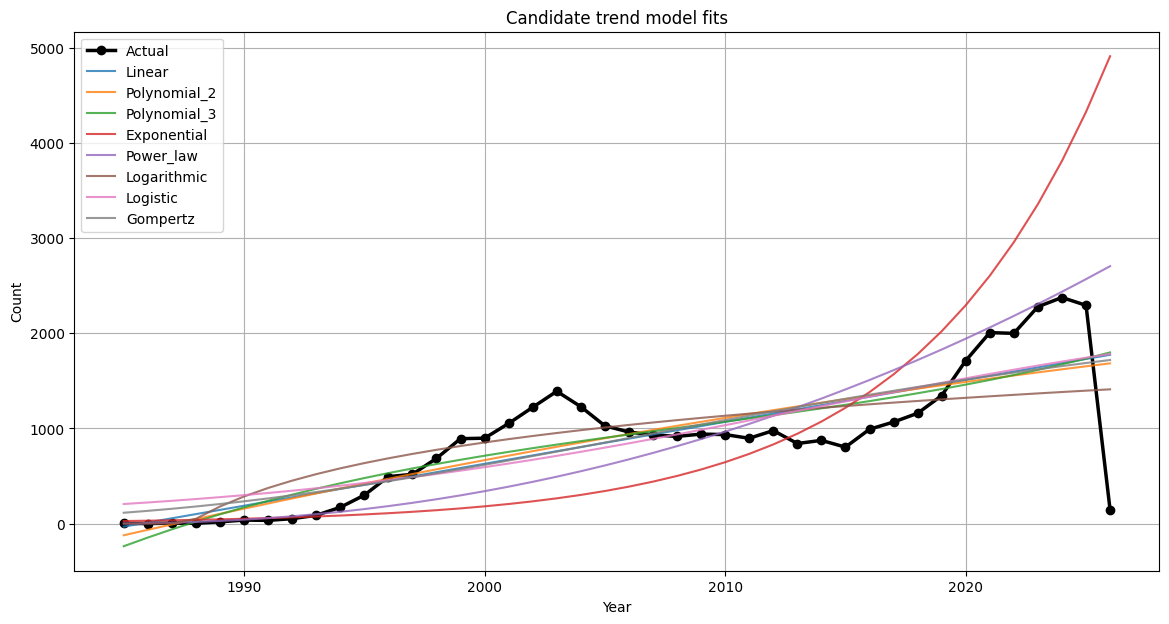

In [16]:
# ============================================================
# 12. PLOT ALL CANDIDATE MODEL FITS
# ============================================================

plt.figure(figsize=(14, 7))
plt.plot(years, y, marker="o", linewidth=2.5, label="Actual", color="black")

for name, pred in predictions.items():
    plt.plot(years, pred, label=name, alpha=0.8)

plt.title("Candidate trend model fits")
plt.xlabel("Year")
plt.ylabel("Count")
plt.legend()
plt.show()


## 7. Structural breaks

Implemented:

- Chow test for a known breakpoint  
- Multiple breakpoint detection using `ruptures`

Use domain knowledge to choose candidate break years. The code also tests all possible breakpoints and reports the strongest.


In [17]:
# ============================================================
# 13. CHOW TEST FOR KNOWN BREAKPOINTS
# ============================================================

def chow_test(year_break, df, y_col="count", t_col="t"):
    left = df[df["year"] <= year_break]
    right = df[df["year"] > year_break]
    if len(left) < 3 or len(right) < 3:
        return None

    y_all = df[y_col].values
    X_all = sm.add_constant(df[[t_col]].values)
    m_all = sm.OLS(y_all, X_all).fit()
    sse_r = np.sum(m_all.resid**2)

    y_l = left[y_col].values
    X_l = sm.add_constant(left[[t_col]].values)
    m_l = sm.OLS(y_l, X_l).fit()

    y_r = right[y_col].values
    X_r = sm.add_constant(right[[t_col]].values)
    m_r = sm.OLS(y_r, X_r).fit()

    sse_u = np.sum(m_l.resid**2) + np.sum(m_r.resid**2)
    k = X_all.shape[1]
    n = len(df)
    F = ((sse_r - sse_u) / k) / (sse_u / (n - 2*k))
    p = 1 - stats.f.cdf(F, k, n - 2*k)
    return {"break_year": year_break, "F": F, "p_value": p, "SSE_restricted": sse_r, "SSE_unrestricted": sse_u}

candidate_breaks = [int(y) for y in df["year"].iloc[3:-3]]
chow_results = [chow_test(b, df) for b in candidate_breaks]
chow_results = [r for r in chow_results if r is not None]
chow_df = pd.DataFrame(chow_results).sort_values("p_value")

display(chow_df.head(10))

best_break = int(chow_df.iloc[0]["break_year"])
print("Strongest single Chow breakpoint:", best_break)


,break_year,F,p_value,SSE_restricted,SSE_unrestricted
35,2023,13.600579,0.000035,6.623214e+06,3.860087e+06
34,2022,10.936503,0.000177,6.623214e+06,4.203599e+06
33,2021,7.271930,0.002118,6.623214e+06,4.789944e+06
32,2020,6.688018,0.003247,6.623214e+06,4.898824e+06
31,2019,4.781897,0.014049,6.623214e+06,5.291465e+06
17,2005,3.660593,0.035169,6.623214e+06,5.553300e+06
18,2006,3.569585,0.037964,6.623214e+06,5.575693e+06
16,2004,3.405247,0.043619,6.623214e+06,5.616589e+06
19,2007,3.291492,0.048048,6.623214e+06,5.645251e+06
20,2008,2.916999,0.066295,6.623214e+06,5.741711e+06


Strongest single Chow breakpoint: 2023


In [18]:
# ============================================================
# 14. MULTIPLE BREAKPOINT DETECTION WITH RUPTURES
# ============================================================

if HAS_RUPTURES:
    signal = df["count"].values.reshape(-1, 1)
    # PELT detects unknown number of breakpoints. Penalty controls sensitivity.
    algo = rpt.Pelt(model="rbf").fit(signal)
    penalty = max(2, np.log(len(signal)) * np.var(signal))
    break_idx = algo.predict(pen=penalty)
    break_years = [int(df.iloc[i-1]["year"]) for i in break_idx if i < len(df)]

    print("Detected break years:", break_years)

    plt.figure(figsize=(12, 5))
    plt.plot(df["year"], df["count"], marker="o", label="Actual")
    for by in break_years:
        plt.axvline(by, linestyle="--", color="red", alpha=0.8, label="Detected break" if by == break_years[0] else None)
    plt.title("Multiple structural break detection")
    plt.xlabel("Year")
    plt.ylabel("Count")
    plt.legend()
    plt.show()
else:
    print("ruptures not installed. Run the setup cell first.")


ruptures not installed. Run the setup cell first.


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.691
Model:                            OLS   Adj. R-squared:                  0.675
Method:                 Least Squares   F-statistic:                     43.57
Date:                Sat, 06 Jun 2026   Prob (F-statistic):           1.15e-10
Time:                        03:20:25   Log-Likelihood:                -307.98
No. Observations:                  42   AIC:                             622.0
Df Residuals:                      39   BIC:                             627.2
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -104.7834    120.119     -0.872      0.3

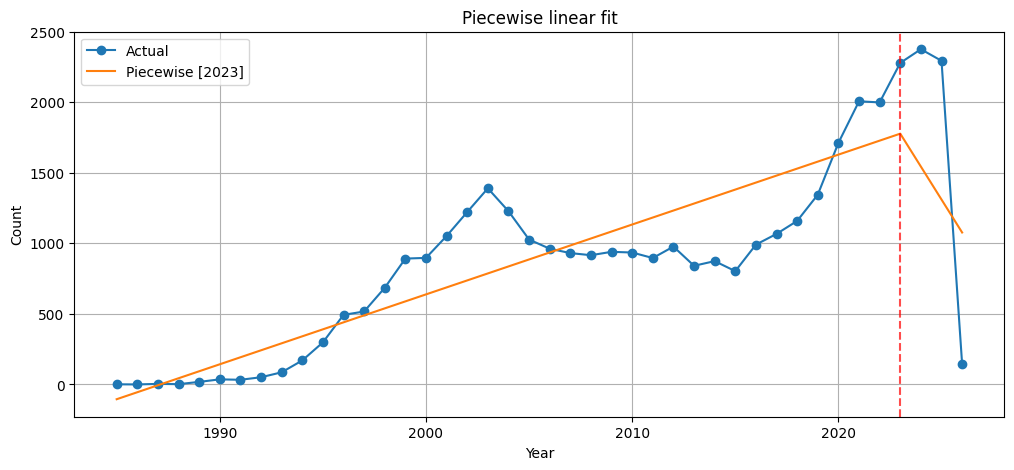

,model,k,R2,Adj_R2,RMSE,MAE,MAPE,SMAPE,SSE,AIC,BIC
8,Piecewise [2023],3,0.690813,0.666403,370.139452,284.280002,398.234136,59.326385,5.754135e+06,502.765906,507.978915
0,Linear,2,0.644115,0.625864,397.109021,283.727964,341.134839,59.329607,6.623214e+06,506.673712,510.149051
1,Polynomial degree 2,3,0.648353,0.620591,394.737414,285.486148,463.246608,58.794814,6.544340e+06,508.170545,513.383554
2,Polynomial degree 3,4,0.654045,0.616644,391.529648,277.847298,750.436279,57.666796,6.438410e+06,509.485144,516.435823
3,Gompertz,3,0.630708,0.601553,404.519552,305.158445,705.452012,61.420455,6.872715e+06,510.226806,515.439815
4,Logarithmic,2,0.605793,0.585577,417.942801,307.446343,205.946315,59.879403,7.336400e+06,510.968945,514.444284
5,Logistic,3,0.613825,0.583337,413.663055,316.273046,1098.523034,62.695401,7.186919e+06,512.104348,517.317357
6,Power law,2,0.339808,0.305952,540.866287,329.042462,99.676149,56.141927,1.228653e+07,532.626456,536.101795
7,Exponential,2,-1.159472,-1.270214,978.201734,587.073076,254.755191,80.463387,4.018890e+07,582.400137,585.875477


In [19]:
# ============================================================
# 15. PIECEWISE LINEAR MODEL USING DETECTED OR BEST BREAKPOINTS
# ============================================================

def fit_piecewise(df, break_years):
    X_parts = [df["t"].values]
    for by in break_years:
        c = df.loc[df["year"] == by, "t"]
        if len(c) == 0:
            continue
        c = float(c.iloc[0])
        X_parts.append(np.maximum(0, df["t"].values - c))
    X_pw = np.column_stack(X_parts)
    X_pw = sm.add_constant(X_pw)
    model = sm.OLS(df["count"].values, X_pw).fit()
    pred = model.predict(X_pw)
    return model, pred

# Use detected breakpoints if available; otherwise use best single Chow breakpoint.
selected_breaks = break_years if ("break_years" in globals() and len(break_years) > 0) else [best_break]

pw_model, pred_pw = fit_piecewise(df, selected_breaks)
predictions["Piecewise"] = pred_pw
piecewise_metrics = model_metrics(y, pred_pw, k=2+len(selected_breaks), model_name=f"Piecewise {selected_breaks}")

print(pw_model.summary())
print(piecewise_metrics)

plt.figure(figsize=(12, 5))
plt.plot(df["year"], df["count"], marker="o", label="Actual")
plt.plot(df["year"], pred_pw, label=f"Piecewise {selected_breaks}")
for by in selected_breaks:
    plt.axvline(by, linestyle="--", color="red", alpha=0.7)
plt.title("Piecewise linear fit")
plt.xlabel("Year")
plt.ylabel("Count")
plt.legend()
plt.show()

metrics_df = pd.concat([metrics_df, pd.DataFrame([piecewise_metrics])], ignore_index=True).drop_duplicates("model", keep="last")
metrics_df = metrics_df.sort_values("AIC")
display(metrics_df)


## 8. Out-of-sample validation

The slides emphasize that **out-of-sample validation overrides in-sample fit**. This section implements:

- fixed train-test split  
- expanding-window validation  


,model,test_RMSE,test_MAE,test_MAPE,test_SMAPE
0,Linear,781.016542,680.655615,148.005758,48.649739
3,Piecewise,781.016542,680.655615,148.005758,48.649739
2,Polynomial_2,1193.391784,1103.757219,92.174911,87.960499
1,Exponential,9689.615543,8684.707888,1835.207493,135.568050


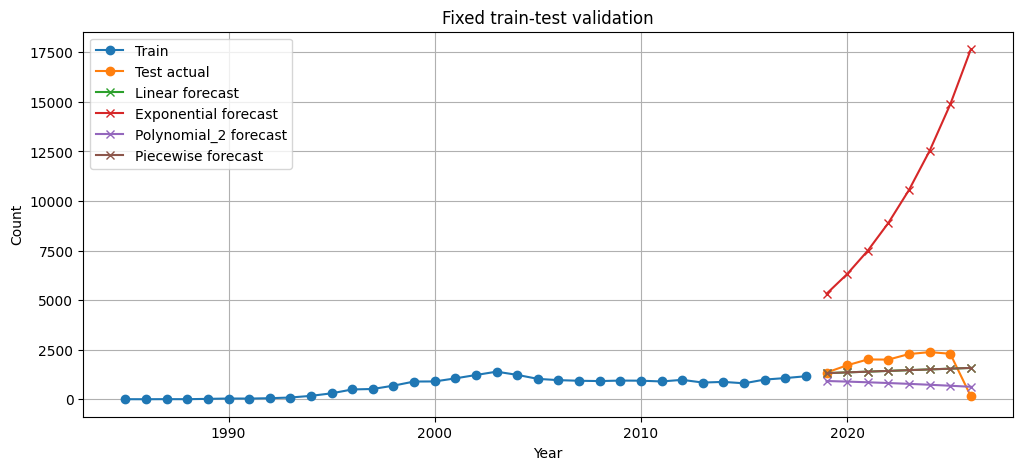

In [20]:
# ============================================================
# 16. FIXED TRAIN-TEST SPLIT
# ============================================================

def fit_predict_model_by_name(train_df, test_df, model_name, break_years_for_piecewise=None):
    t_train = train_df["t"].values.astype(float)
    y_train = train_df["count"].values.astype(float)
    t_all = np.concatenate([train_df["t"].values, test_df["t"].values]).astype(float)
    t_test = test_df["t"].values.astype(float)

    if model_name == "Linear":
        model = sm.OLS(y_train, sm.add_constant(t_train)).fit()
        return model.predict(sm.add_constant(t_test))

    if model_name == "Exponential":
        model = sm.OLS(np.log1p(y_train), sm.add_constant(t_train)).fit()
        return np.maximum(np.expm1(model.predict(sm.add_constant(t_test))), 0)

    if model_name == "Polynomial_2":
        X_train = sm.add_constant(np.column_stack([t_train, t_train**2]))
        model = sm.OLS(y_train, X_train).fit()
        X_test = sm.add_constant(np.column_stack([t_test, t_test**2]))
        return np.maximum(model.predict(X_test), 0)

    if model_name == "Piecewise":
        breaks = break_years_for_piecewise or []
        X_train_parts = [t_train]
        X_test_parts = [t_test]
        for by in breaks:
            c_match = df.loc[df["year"] == by, "t"]
            if len(c_match) == 0:
                continue
            c = float(c_match.iloc[0])
            X_train_parts.append(np.maximum(0, t_train - c))
            X_test_parts.append(np.maximum(0, t_test - c))
        X_train = sm.add_constant(np.column_stack(X_train_parts))
        X_test = sm.add_constant(np.column_stack(X_test_parts))
        model = sm.OLS(y_train, X_train).fit()
        return np.maximum(model.predict(X_test), 0)

    raise ValueError(f"Unknown model: {model_name}")

# Use final 20% as test set
test_size = max(3, int(len(df) * 0.2))
train_df = df.iloc[:-test_size].copy()
test_df = df.iloc[-test_size:].copy()

validation_rows = []
for m in ["Linear", "Exponential", "Polynomial_2", "Piecewise"]:
    try:
        pred_test = fit_predict_model_by_name(train_df, test_df, m, selected_breaks)
        validation_rows.append({
            "model": m,
            "test_RMSE": np.sqrt(mean_squared_error(test_df["count"], pred_test)),
            "test_MAE": mean_absolute_error(test_df["count"], pred_test),
            "test_MAPE": safe_mape(test_df["count"], pred_test),
            "test_SMAPE": smape(test_df["count"], pred_test)
        })
    except Exception as e:
        validation_rows.append({"model": m, "error": str(e)})

validation_df = pd.DataFrame(validation_rows).sort_values("test_RMSE")
display(validation_df)

plt.figure(figsize=(12, 5))
plt.plot(train_df["year"], train_df["count"], marker="o", label="Train")
plt.plot(test_df["year"], test_df["count"], marker="o", label="Test actual")
for m in ["Linear", "Exponential", "Polynomial_2", "Piecewise"]:
    try:
        pred_test = fit_predict_model_by_name(train_df, test_df, m, selected_breaks)
        plt.plot(test_df["year"], pred_test, marker="x", label=f"{m} forecast")
    except Exception:
        pass
plt.title("Fixed train-test validation")
plt.xlabel("Year")
plt.ylabel("Count")
plt.legend()
plt.show()


In [21]:
# ============================================================
# 17. EXPANDING-WINDOW VALIDATION
# ============================================================

def expanding_window_validation(df, model_name, min_train=10, break_years_for_piecewise=None):
    rows = []
    for split in range(min_train, len(df)-1):
        train = df.iloc[:split].copy()
        test = df.iloc[split:split+1].copy()
        try:
            pred = fit_predict_model_by_name(train, test, model_name, break_years_for_piecewise)
            rows.append({
                "year": int(test["year"].iloc[0]),
                "actual": float(test["count"].iloc[0]),
                "pred": float(pred[0]),
                "abs_error": abs(float(test["count"].iloc[0]) - float(pred[0]))
            })
        except Exception as e:
            rows.append({"year": int(test["year"].iloc[0]), "actual": float(test["count"].iloc[0]), "pred": np.nan, "abs_error": np.nan})
    out = pd.DataFrame(rows)
    return out

ew_rows = []
for m in ["Linear", "Exponential", "Polynomial_2", "Piecewise"]:
    ev = expanding_window_validation(df, m, min_train=max(8, len(df)//3), break_years_for_piecewise=selected_breaks)
    ew_rows.append({
        "model": m,
        "expanding_RMSE": np.sqrt(mean_squared_error(ev["actual"].dropna(), ev["pred"].dropna())) if ev["pred"].notna().sum() else np.nan,
        "expanding_MAE": mean_absolute_error(ev["actual"].dropna(), ev["pred"].dropna()) if ev["pred"].notna().sum() else np.nan,
        "expanding_MAPE": safe_mape(ev["actual"], ev["pred"])
    })

expanding_df = pd.DataFrame(ew_rows).sort_values("expanding_RMSE")
display(expanding_df)


,model,expanding_RMSE,expanding_MAE,expanding_MAPE
0,Linear,NaN,NaN,NaN
1,Exponential,NaN,NaN,NaN
2,Polynomial_2,NaN,NaN,NaN
3,Piecewise,NaN,NaN,NaN


## 9. ARIMA forecasting

ARIMA is useful for short-term forecasting after stationarity transformation. For long-term technology forecasting, compare it against structural and nonlinear models.


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood op

Best ARIMA order: (1, 2, 2) AIC: 579.830404303262 BIC: 586.5859221197177


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


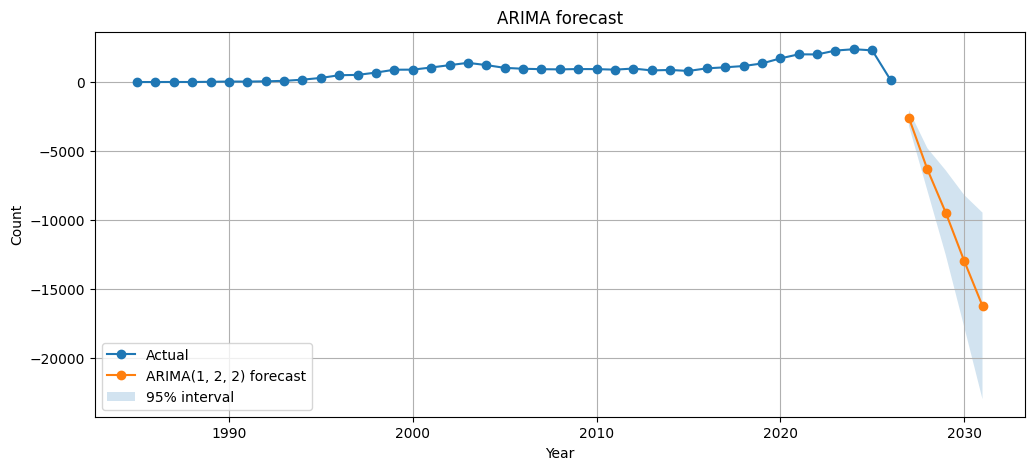

In [22]:
# ============================================================
# 18. ARIMA GRID SEARCH AND FORECAST
# ============================================================

def fit_best_arima(y, max_p=3, max_d=2, max_q=3):
    best = None
    for p in range(max_p+1):
        for d in range(max_d+1):
            for q in range(max_q+1):
                if p == 0 and d == 0 and q == 0:
                    continue
                try:
                    model = ARIMA(y, order=(p,d,q)).fit()
                    row = {"order": (p,d,q), "AIC": model.aic, "BIC": model.bic, "model": model}
                    if best is None or row["AIC"] < best["AIC"]:
                        best = row
                except Exception:
                    continue
    return best

best_arima = fit_best_arima(df["count"].values, max_p=3, max_d=2, max_q=3)
print("Best ARIMA order:", best_arima["order"], "AIC:", best_arima["AIC"], "BIC:", best_arima["BIC"])

forecast_steps = 5
arima_forecast = best_arima["model"].get_forecast(steps=forecast_steps)
future_years = np.arange(df["year"].max()+1, df["year"].max()+1+forecast_steps)
arima_mean = arima_forecast.predicted_mean
arima_ci = arima_forecast.conf_int()

plt.figure(figsize=(12, 5))
plt.plot(df["year"], df["count"], marker="o", label="Actual")
plt.plot(future_years, arima_mean, marker="o", label=f"ARIMA{best_arima['order']} forecast")
plt.fill_between(future_years, arima_ci[:,0], arima_ci[:,1], alpha=0.2, label="95% interval")
plt.title("ARIMA forecast")
plt.xlabel("Year")
plt.ylabel("Count")
plt.legend()
plt.show()


## 10. Forecast future values from selected model

This section selects the best model based on out-of-sample validation and generates 5-year forecasts.

For publication or executive reporting, always state:

- selected model  
- assumptions  
- uncertainty  
- whether structural breaks are possible  


Selected model based on validation: Linear


,year,t,forecast
0,2027,42,1817.868757
1,2028,43,1861.944602
2,2029,44,1906.020447
3,2030,45,1950.096291
4,2031,46,1994.172136


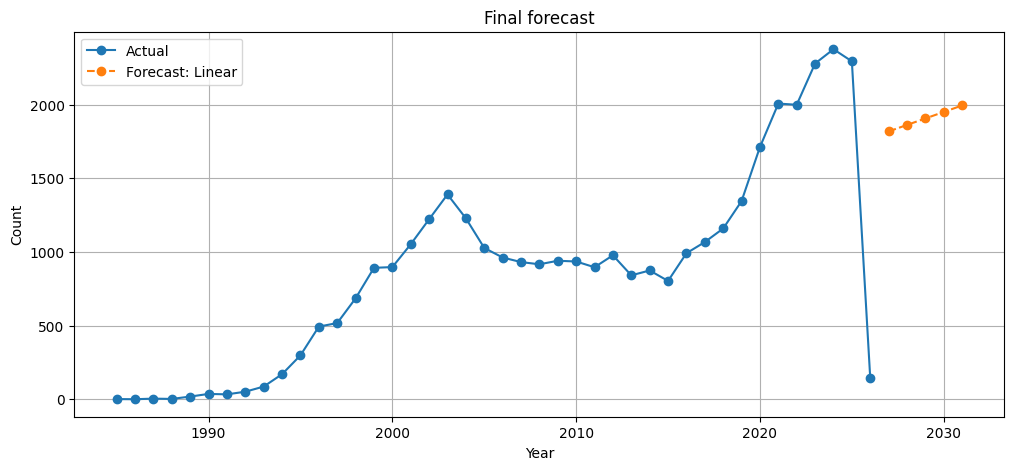

In [23]:
# ============================================================
# 19. FINAL MODEL SELECTION AND 5-YEAR FORECAST
# ============================================================

# Choose model with lowest fixed test RMSE if available.
if "validation_df" in globals() and "test_RMSE" in validation_df.columns:
    final_model_name = validation_df.dropna(subset=["test_RMSE"]).iloc[0]["model"]
else:
    final_model_name = metrics_df.iloc[0]["model"]

print("Selected model based on validation:", final_model_name)

future_steps = 5
future = pd.DataFrame({
    "year": np.arange(df["year"].max()+1, df["year"].max()+1+future_steps),
})
future["t"] = np.arange(df["t"].max()+1, df["t"].max()+1+future_steps)

# Fit on all data and forecast depending on selected model.
def forecast_selected(df, future, model_name, selected_breaks):
    train = df.copy()
    fut = future.copy()
    t_train = train["t"].values.astype(float)
    y_train = train["count"].values.astype(float)
    t_future = fut["t"].values.astype(float)

    if model_name == "Linear":
        model = sm.OLS(y_train, sm.add_constant(t_train)).fit()
        return np.maximum(model.predict(sm.add_constant(t_future)), 0)

    if model_name == "Exponential":
        model = sm.OLS(np.log1p(y_train), sm.add_constant(t_train)).fit()
        return np.maximum(np.expm1(model.predict(sm.add_constant(t_future))), 0)

    if model_name in ["Polynomial_2", "Polynomial degree 2"]:
        X_train = sm.add_constant(np.column_stack([t_train, t_train**2]))
        X_future = sm.add_constant(np.column_stack([t_future, t_future**2]))
        model = sm.OLS(y_train, X_train).fit()
        return np.maximum(model.predict(X_future), 0)

    if model_name == "Piecewise" or str(model_name).startswith("Piecewise"):
        breaks = selected_breaks
        X_train_parts = [t_train]
        X_future_parts = [t_future]
        for by in breaks:
            c_match = df.loc[df["year"] == by, "t"]
            if len(c_match) == 0:
                continue
            c = float(c_match.iloc[0])
            X_train_parts.append(np.maximum(0, t_train - c))
            X_future_parts.append(np.maximum(0, t_future - c))
        model = sm.OLS(y_train, sm.add_constant(np.column_stack(X_train_parts))).fit()
        return np.maximum(model.predict(sm.add_constant(np.column_stack(X_future_parts))), 0)

    # Fallback: ARIMA
    best = fit_best_arima(y_train)
    return np.maximum(best["model"].get_forecast(steps=len(fut)).predicted_mean, 0)

future["forecast"] = forecast_selected(df, future, final_model_name, selected_breaks)

display(future)

plt.figure(figsize=(12, 5))
plt.plot(df["year"], df["count"], marker="o", label="Actual")
plt.plot(future["year"], future["forecast"], marker="o", linestyle="--", label=f"Forecast: {final_model_name}")
plt.title("Final forecast")
plt.xlabel("Year")
plt.ylabel("Count")
plt.legend()
plt.show()


## 11. Final model comparison table

This table combines in-sample fit and out-of-sample validation. Use it as the basis for your final reporting.


In [24]:
# ============================================================
# 20. FINAL MODEL COMPARISON TABLE
# ============================================================

model_comparison = metrics_df.copy()

# Merge fixed validation if available
if "validation_df" in globals():
    model_comparison = model_comparison.merge(validation_df, on="model", how="left")

# Add expanding window validation if available
if "expanding_df" in globals():
    model_comparison = model_comparison.merge(expanding_df, on="model", how="left")

# Sort by validation first, then AIC
sort_cols = [c for c in ["test_RMSE", "AIC"] if c in model_comparison.columns]
model_comparison = model_comparison.sort_values(sort_cols)

display(model_comparison)

# Save results
model_comparison.to_csv("model_comparison_results.csv", index=False)
df.to_csv("processed_series_with_indicators.csv", index=False)
future.to_csv("forecast_results.csv", index=False)

print("Saved:")
print("- processed_series_with_indicators.csv")
print("- model_comparison_results.csv")
print("- forecast_results.csv")


,model,k,R2,Adj_R2,RMSE,MAE,MAPE,SMAPE,SSE,AIC,BIC,test_RMSE,test_MAE,test_MAPE,test_SMAPE,expanding_RMSE,expanding_MAE,expanding_MAPE
1,Linear,2,0.644115,0.625864,397.109021,283.727964,341.134839,59.329607,6.623214e+06,506.673712,510.149051,781.016542,680.655615,148.005758,48.649739,NaN,NaN,NaN
8,Exponential,2,-1.159472,-1.270214,978.201734,587.073076,254.755191,80.463387,4.018890e+07,582.400137,585.875477,9689.615543,8684.707888,1835.207493,135.568050,NaN,NaN,NaN
0,Piecewise [2023],3,0.690813,0.666403,370.139452,284.280002,398.234136,59.326385,5.754135e+06,502.765906,507.978915,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Polynomial degree 2,3,0.648353,0.620591,394.737414,285.486148,463.246608,58.794814,6.544340e+06,508.170545,513.383554,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Polynomial degree 3,4,0.654045,0.616644,391.529648,277.847298,750.436279,57.666796,6.438410e+06,509.485144,516.435823,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Gompertz,3,0.630708,0.601553,404.519552,305.158445,705.452012,61.420455,6.872715e+06,510.226806,515.439815,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Logarithmic,2,0.605793,0.585577,417.942801,307.446343,205.946315,59.879403,7.336400e+06,510.968945,514.444284,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Logistic,3,0.613825,0.583337,413.663055,316.273046,1098.523034,62.695401,7.186919e+06,512.104348,517.317357,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Power law,2,0.339808,0.305952,540.866287,329.042462,99.676149,56.141927,1.228653e+07,532.626456,536.101795,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Saved:
- processed_series_with_indicators.csv
- model_comparison_results.csv
- forecast_results.csv


## 12. Interpretation template

Use this reporting template after running the notebook:

1. **Data structure:** years, number of observations, missing years, zeros.  
2. **Exploratory result:** raw trend shape, log-scale shape, acceleration pattern.  
3. **Trend detection:** Mann-Kendall p-value, Sen's slope, Spearman result.  
4. **Stationarity:** ADF/KPSS results and implication for ARIMA.  
5. **Model comparison:** compare R², RMSE, AIC, BIC, and validation errors.  
6. **Structural breaks:** Chow/Bai-Perron/ruptures break years and interpretation.  
7. **Final model:** selected model, why selected, limitations.  
8. **Forecast:** point forecasts + uncertainty discussion.  

**Important:** If structural breaks exist, do not trust a single global linear/exponential model. Use piecewise, regime-based, or scenario forecasting.
